# **Customer Sentiment Analysis**

## Modules

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Dataset

In [2]:
data = pd.read_csv("data/raw/customer_reviews_sentiment_practice.csv")
data.head()

,review_id,customer_id,review_date,product_category,product_name,rating,review_title,review_text,sentiment,verified_purchase
0,REV0001,C1174,2025-04-15,Electronics,Smart Watch,4,Issue with product,Customer support solved my issue quickly. Very...,positive,Yes
1,REV0002,C1007,2026-09-09,Beauty,Face Moisturizer,4,Satisfied,Very happy with this purchase. Delivery was qu...,positive,Yes
2,REV0003,C1088,2026-03-09,Beauty,Face Moisturizer,4,Review,Customer support solved my issue quickly. Very...,positive,Yes
3,REV0004,C1092,2025-04-10,Home,Air Fryer,3,Everyday use,Packaging was fine. I have not used it enough ...,neutral,No
4,REV0005,C1076,2026-07-20,Fashion,Running Shoes,3,Everyday use,It does the basic job without any extra benefits.,neutral,No


In [3]:
# Number of recored and column
print("Total Recoreds:", data.shape[0])
print("Total Columns:", data.shape[1])

Total Recoreds: 600
Total Columns: 10


In [4]:
# Data Types
print("DataTypes:", data.dtypes)

DataTypes: review_id              str
customer_id            str
review_date            str
product_category       str
product_name           str
rating               int64
review_title           str
review_text            str
sentiment              str
verified_purchase      str
dtype: object


In [5]:
# Missing Values
data.isnull().sum()

review_id            0
customer_id          0
review_date          0
product_category     0
product_name         0
rating               0
review_title         0
review_text          0
sentiment            0
verified_purchase    0
dtype: int64

In [6]:
# Total duplicate records
print("Duplicate Records:", data.duplicated().sum())

Duplicate Records: 0


In [7]:
# Date range
review_dates = pd.to_datetime(data["review_date"], errors="coerce")
print("Date Range:")
print("Start Date:", review_dates.min())
print("End Date:", review_dates.max())

Date Range:
Start Date: 2025-01-04 00:00:00
End Date: 2026-10-13 00:00:00


In [8]:
# Sentiment class distribution
print("Sentiment Distribution:")
print(data["sentiment"].value_counts())

Sentiment Distribution:
sentiment
positive    246
negative    196
neutral     127
mixed        31
Name: count, dtype: int64


In [9]:
# Sentiment distribution in percentage
print("Sentiment Distribution (%):")
print((data["sentiment"].value_counts(normalize=True) * 100).round(2))

Sentiment Distribution (%):
sentiment
positive    41.00
negative    32.67
neutral     21.17
mixed        5.17
Name: proportion, dtype: float64


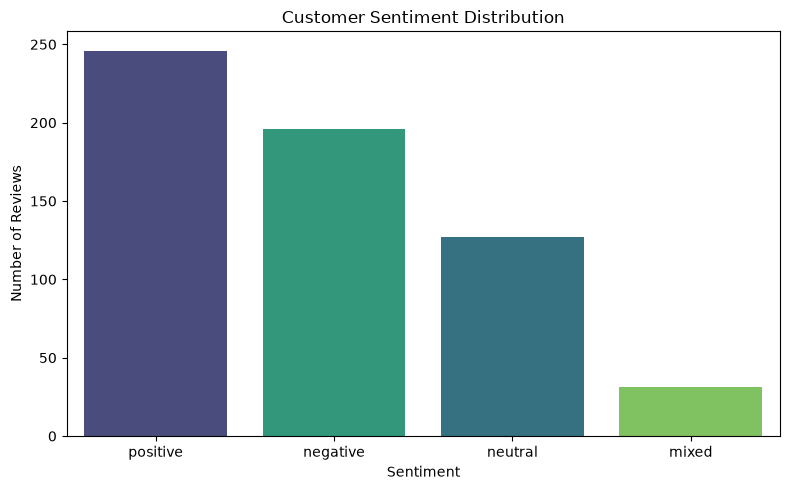

In [10]:
# Sentiment Analysis
plt.figure(figsize=(8, 5))
sns.countplot(
    data=data,
    x="sentiment",
    hue="sentiment",
    order=data["sentiment"].value_counts().index,
    palette="viridis",
    legend=False
)
plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()

### Business Interpretation

- Positive reviews have the highest count, indicating that most customers have shared positive feedback.
- Negative reviews are the second-highest category, showing that a considerable number of customers have experienced dissatisfaction.
- Neutral reviews represent a smaller portion of the feedback, indicating reviews without clearly positive or negative opinions.
- Mixed reviews have the lowest count, suggesting that fewer customers have expressed both positive and negative opinions in the same review.

**Business Insight:** Although customer feedback is mostly positive, businesses should investigate negative reviews to identify areas for improvement and enhance overall customer satisfaction.

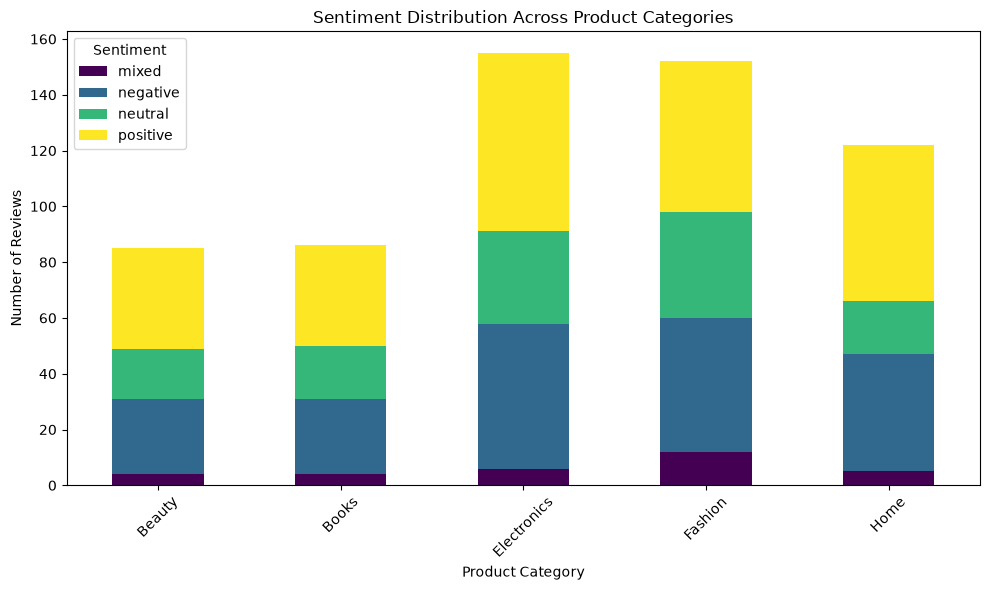

In [11]:
# Sentiment Across Product Category
category_sentiment = pd.crosstab(
    data["product_category"],
    data["sentiment"]
)
category_sentiment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    colormap="viridis"
)
plt.title("Sentiment Distribution Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()

### Business Interpretation

- Electronics and Fashion have the highest number of customer reviews, indicating greater customer feedback activity in these categories.
- Positive reviews form the largest sentiment segment across all five product categories, suggesting an overall positive customer response.
- Electronics and Fashion also have a considerable number of negative reviews, indicating areas where businesses may need to investigate customer complaints.
- Beauty and Books have comparatively fewer reviews than the other categories.
- Mixed sentiment reviews are relatively low across all categories.

**Business Insight:** Businesses should focus on improving customer experiences in Electronics and Fashion by investigating negative feedback while maintaining the factors contributing to positive customer reviews.

In [12]:
# Create a separate working copy of the original dataset
data_work = data.copy(deep=True)

# Verify that both datasets have the same dimensions
print("Original Dataset Shape:", data.shape)
print("Working Copy Shape:", data_work.shape)

# Verify that the original dataset remains unchanged
print("Original Dataset Unchanged:", data.equals(data_work))

Original Dataset Shape: (600, 10)
Working Copy Shape: (600, 10)
Original Dataset Unchanged: True


In [13]:
from NLP.functions.text_preprocessing import clean_review

data_work["cleaned_text"] = data_work["review_text"].apply(clean_review)
data_work[["review_text", "cleaned_text"]].head(10)

,review_text,cleaned_text
0,Customer support solved my issue quickly. Very...,customer support solved my issue quickly very ...
1,Very happy with this purchase. Delivery was qu...,very happy with this purchase delivery was quick
2,Customer support solved my issue quickly. Very...,customer support solved my issue quickly very ...
3,Packaging was fine. I have not used it enough ...,packaging was fine i have not used it enough t...
4,It does the basic job without any extra benefits.,it does the basic job without any extra benefits
5,Very disappointing quality. It stopped working...,very disappointing quality it stopped working ...
6,Uncomfortable to use and the material feels ch...,uncomfortable to use and the material feels cheap
7,Customer support did not respond to my complaint.,customer support did not respond to my complaint
8,The product is okay and works as expected.,the product is okay and works as expected
9,"Comfortable, useful, and worth the price.",comfortable useful and worth the price


We preserve not and never because removing these words can reverse the meaning of a customer review. For example, "not good" could become "good", leading to an incorrect sentiment.

In [14]:
for i in range(5):
    print("Original:", data_work["review_text"].iloc[i])
    print("Cleaned:", data_work["cleaned_text"].iloc[i])
    print("-" * 70)

Original: Customer support solved my issue quickly. Very satisfied.
Cleaned: customer support solved my issue quickly very satisfied
----------------------------------------------------------------------
Original: Very happy with this purchase. Delivery was quick.
Cleaned: very happy with this purchase delivery was quick
----------------------------------------------------------------------
Original: Customer support solved my issue quickly. Very satisfied.
Cleaned: customer support solved my issue quickly very satisfied
----------------------------------------------------------------------
Original: Packaging was fine. I have not used it enough to judge.
Cleaned: packaging was fine i have not used it enough to judge
----------------------------------------------------------------------
Original: It does the basic job without any extra benefits.
Cleaned: it does the basic job without any extra benefits
----------------------------------------------------------------------
